# How much does picking the best of K inflate a score, and how to fix it?

- This notebook measures the winner's curse on real runs and real prompt
  variants, and picks a correction to report with a score (Milestone 4)
  - It is Studies F, G, and H of `preregistration_3.md`, whose design and
    predictions were committed before any of it was run
  - Milestone 4 so far only simulated the curse; here the variants are real
- The pedagogical arc:
  - Reporting the best of K runs, where every difference is luck
  - Reporting the best of K prompt variants, scored on tasks the selection
    never saw
  - Which of 5 corrections recovers the winner's true score, and a fix for
    the one that misses the most (an extra look)
  - The reporting protocol of the project, on the SWE-bench Verified
    leaderboard
  - Which predictions held, and the takeaways

In [1]:
%load_ext autoreload
%autoreload 2

import logging

In [2]:
import numpy as np
import pandas as pd

import helpers.hdbg as hdbg
import helpers.hnotebook as hnotebook

import skill_vs_luck_runs_utils as rutils
import skill_vs_luck_utils as utils

# Initialize notebook configuration and logging.
hnotebook.config_notebook()
_LOG = logging.getLogger(__name__)
rutils.init_loggers(_LOG)

# Convert `display` into `print()` when running outside IPython.
try:
    from IPython.display import display
except ImportError:
    display = print  # type: ignore

/usr/local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


INFO  > /usr/local/lib/python3.12/site-packages/ipykernel_launcher.py -f /tmp/tmp2f50vepb.json --HistoryManager.hist_file=:memory:


In [3]:
# Settings of the analysis.
config = {
    "phase_1_dir": "data/coding_runs",
    "phase_2_dir": "data/coding_runs_phase2",
    "variants_dir": "data/coding_runs_variants",
    "swebench_dir": "data",
    "k_public": [2, 5, 10, 20],
    "k_variants": [2, 5, 10, 20],
    "n_draws": 500,
    "n_trials": 1000,
    "seed": 0,
    "figsize": (10, 5),
}
CORRECTIONS = list(utils.WINNER_CORRECTIONS)

# Part 1: Reporting the best of K runs (Study F)

## Cell 1.1: The cells with several runs on the same tasks

- Public cells: the EvalPlus samples on HumanEval+, 50 scored runs per task
- Local cells: our runs, 5 per task in phase 1 and 3 in Studies C and D, each
  scaffold

In [4]:
# Collect the tasks x runs matrix of each cell.
cells = {}
public_scores = rutils.load_scores(
    config["phase_1_dir"], pattern="evalplus_humaneval_*_t0.[28].csv.gz"
)
for (model, temperature), _ in public_scores.groupby(["model", "temperature"]):
    cells[("public", model, temperature, "humaneval", "one_shot")] = (
        rutils.get_outcome_matrix(
            public_scores,
            source="evalplus",
            benchmark="humaneval",
            model=model,
            scaffold="one_shot",
            temperature=temperature,
        )
    )
for scores_dir in (config["phase_1_dir"], config["phase_2_dir"]):
    local_scores = rutils.load_scores(
        scores_dir, pattern="local_*_t0.[28].csv.gz"
    )
    groups = local_scores.groupby(
        ["model", "temperature", "benchmark", "scaffold"]
    )
    for (model, temperature, benchmark, scaffold), _ in groups:
        key = ("local", model, temperature, benchmark, scaffold)
        # Phases 1 and 2 must not have the same cell.
        hdbg.dassert_not_in(key, cells)
        cells[key] = rutils.get_outcome_matrix(
            local_scores,
            source="local",
            benchmark=benchmark,
            model=model,
            scaffold=scaffold,
            temperature=temperature,
        )
cell_table = pd.DataFrame(
    [(*key, matrix.shape[0], matrix.shape[1]) for key, matrix in cells.items()],
    columns=[
        "group",
        "model",
        "temperature",
        "benchmark",
        "scaffold",
        "n_tasks",
        "n_runs",
    ],
)
display(cell_table.groupby(["group", "n_runs"]).size().rename("n_cells"))

group   n_runs
local   3         18
        5         12
public  50        17
Name: n_cells, dtype: int64

## Cell 1.2: The best of K runs against the runs left out

- For each cell and `K`, 500 draws of `K` runs: the inflation is the best of
  the `K` runs minus the mean of the runs left out
- The predicted inflation is `sigma_run x E[max of K]`, from the run noise of
  the cell
- Each correction is applied to the best run from the `K` runs only, and its
  error is measured against the runs left out

In [5]:
# Draw the best of K runs in every cell, and keep the draws for Cell 3.2.
rows = []
runs_draws = {}
for key, matrix in cells.items():
    group = key[0]
    n_runs = matrix.shape[1]
    # The public cells use every K; the local cells K = 2, and also K = 3
    # for the 5-run cells of phase 1, so that 2 runs are left out.
    if group == "public":
        k_values = config["k_public"]
    else:
        k_values = [2, 3] if n_runs == 5 else [2]
    for k in k_values:
        draws = utils.simulate_best_of_k_runs(
            matrix, k, n_draws=config["n_draws"], seed=config["seed"]
        )
        runs_draws[(key, k)] = draws
        summary = utils.summarize_corrections(draws, "truth")
        row = dict(zip(cell_table.columns[:5], key))
        row.update(
            {
                "k": k,
                "n_runs": n_runs,
                "inflation": 100 * draws["inflation"].mean(),
                "predicted": 100 * draws["predicted"].mean(),
            }
        )
        for correction in CORRECTIONS:
            row[f"error_{correction}"] = summary.loc[correction, "mean_error"]
            row[f"rmse_{correction}"] = summary.loc[correction, "rmse"]
        rows.append(row)
runs_cells = pd.DataFrame(rows)
display(
    runs_cells[runs_cells["k"] == 5][
        ["model", "temperature", "inflation", "predicted"]
    ].round(2)
)

,model,temperature,inflation,predicted
1,chatgpt,0.8,3.12,2.67
5,code-llama-13b,0.2,2.57,2.14
9,code-llama-13b,0.8,3.12,3.09
13,code-llama-34b,0.2,2.44,2.43
17,code-llama-34b,0.8,2.97,3.23
21,code-llama-7b,0.2,2.17,2.01
25,code-llama-7b,0.8,2.77,2.94
29,codegen-16b,0.2,1.49,1.79
33,codegen-16b,0.8,2.26,2.43
37,codet5p-16b,0.2,2.45,1.95


## Cell 1.3: The public cells and the local cells, pooled

In [6]:
# Pool the cells of each group, with the RMSE pooled over all the draws.
error_columns = [f"error_{c}" for c in CORRECTIONS]
rmse_columns = [f"rmse_{c}" for c in CORRECTIONS]
grouped = runs_cells.groupby(["group", "k"])
runs_pooled = grouped[["inflation", "predicted"] + error_columns].mean()
runs_pooled[rmse_columns] = np.sqrt(
    (runs_cells[rmse_columns] ** 2)
    .groupby([runs_cells["group"], runs_cells["k"]])
    .mean()
)
runs_pooled["ratio"] = runs_pooled["inflation"] / runs_pooled["predicted"]
runs_pooled["n_cells"] = grouped.size()
display(runs_pooled.round(2))

inflation  predicted  error_none  error_binomial  error_paired  error_empirical_bayes  error_conditional  rmse_none  rmse_binomial  rmse_paired  rmse_empirical_bayes  rmse_conditional  ratio  n_cells
group  k                                                                                                                                                                                                          
local  2        1.24       0.88        1.24           -0.52          0.21                   0.48               0.05       2.98           2.77         2.69                  2.64              5.51   1.41       30
       3        1.69       1.43        1.69           -0.83          0.10                   0.44              -2.09       2.41           1.90         1.69                  1.83             11.49   1.18       12
public 2        1.16       1.16        1.16           -0.85         -0.01                   0.38              -2.06       2.19           2.02         1.84                  1.81             11.43   1.00       17
       5        2.49       2.40        2.49           -1.68          0.08                   0.55              -3.73       2.94           2.28         1.50                  1.47             17.34   1.04       17
       10       3.25       3.17        3.25           -2.29          0.06                   0.52              -4.04       3.56           2.69         1.32                  1.24             17.36   1.03       17
       20       4.00       3.85        4.00           -2.76          0.12                   0.49              -4.14       4.23           3.08         1.19                  1.06             18.92   1.04       17

## Cell 1.4: The predicted inflation with few runs (extra look)

- Not in `preregistration_3.md`: added after Cell 1.3 showed the local cells
  above their prediction
- The prediction estimates the run noise from the pass rate `p_t` of each
  task over the `R` runs of the cell, and `p_t (1 - p_t)` from `R` runs is too
  low by a factor `(R - 1) / R`: 2 / 3 with 3 runs, while the public cells have
  50 runs
- Multiplying the predicted inflation by `sqrt(R / (R - 1))` removes that bias

In [7]:
# Correct the prediction for the number of runs of each cell.
runs_cells["predicted_unbiased"] = runs_cells["predicted"] * np.sqrt(
    runs_cells["n_runs"] / (runs_cells["n_runs"] - 1)
)
unbiased = runs_cells.groupby(["group", "k"])[
    ["inflation", "predicted", "predicted_unbiased"]
].mean()
unbiased["ratio_unbiased"] = (
    unbiased["inflation"] / unbiased["predicted_unbiased"]
)
display(unbiased.round(2))

inflation  predicted  predicted_unbiased  ratio_unbiased
group  k                                                           
local  2        1.24       0.88                1.03            1.20
       3        1.69       1.43                1.60            1.06
public 2        1.16       1.16                1.17            0.99
       5        2.49       2.40                2.42            1.03
       10       3.25       3.17                3.20            1.02
       20       4.00       3.85                3.89            1.03

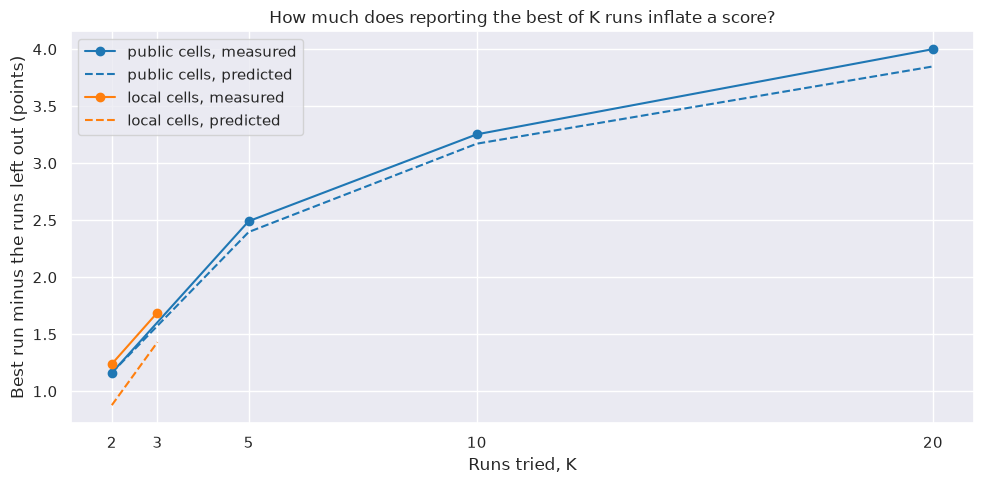

In [8]:
# Plot the measured and the predicted inflation.
rutils.plot_best_of_k(runs_pooled, figsize=config["figsize"])

# Part 2: Reporting the best of K prompt variants (Study G)

## Cell 2.1: The 20 prompt variants of DeepSeek Coder 1.3B

- Greedy one-shot answers to every task, with each variant of
  `PROMPT_VARIANTS`: 2 system prompts x 2 instructions x 5 lines of guidance
- Made by `run_prompt_variants.sh` on 2026-11-26 and 27, with Ollama 0.40.16
  and the same model file as phase 1, which used Ollama 0.40.8
- 33 MBPP+ answers were first made by 2 extra streams running at the same
  time; Ollama can batch parallel requests, which can change greedy answers,
  so those 33 were deleted and made again one at a time
- 1 MBPP+ answer is empty: Ollama stopped it for repeating a token, and it
  counts as a failure
- The table gives the score of each variant in percent, and the number of
  answers cut at the limit of 768 tokens (`truncated`)

In [9]:
# Load the scores of the variants.
variant_scores = rutils.load_scores(config["variants_dir"])
variant_matrices = {
    benchmark: rutils.get_variant_matrix(variant_scores, benchmark)
    for benchmark in rutils.BENCHMARKS
}
variant_table = pd.DataFrame(
    {
        benchmark: 100 * matrix.mean(axis=1)
        for benchmark, matrix in variant_matrices.items()
    }
)
# Count the answers cut at the token limit, which the guidance can change.
one_shot = variant_scores[variant_scores["scaffold"] == "one_shot"]
truncated = one_shot.pivot_table(
    index="variant", columns="benchmark", values="truncated", aggfunc="sum"
)
variant_table = variant_table.join(truncated.add_suffix("_truncated"))
display(variant_table.sort_values("humaneval", ascending=False).round(1))

,humaneval,mbpp,humaneval_truncated,mbpp_truncated
expert-evalplus-examples,60.4,52.9,0,2
none-short-none,59.8,53.4,0,1
expert-short-examples,59.8,53.2,0,4
none-evalplus-none,59.1,53.7,0,5
none-evalplus-examples,59.1,53.7,0,2
expert-short-clean,59.1,49.5,0,1
none-evalplus-signature,59.1,52.4,0,1
none-short-signature,59.1,52.1,0,1
expert-short-none,58.5,52.1,0,1
expert-evalplus-signature,58.5,52.6,0,1


## Cell 2.2: The baseline variant repeats phase 1

- The baseline variant sends the prompt of phase 1, so its outcomes should
  be those of the greedy one-shot run of phase 1
- The 2 runs used different versions of Ollama (0.40.8 and 0.40.16), which
  can change a few greedy answers

In [10]:
# Compare the baseline variant with the greedy one-shot run of phase 1.
phase_1_greedy = rutils.load_scores(
    config["phase_1_dir"],
    pattern="local_*_deepseek-coder_1.3b-instruct-q4_K_M_t0.csv.gz",
)
agreement = {}
for benchmark, matrix in variant_matrices.items():
    phase_1 = rutils.get_outcome_matrix(
        phase_1_greedy,
        source="local",
        benchmark=benchmark,
        model=rutils.PHASE_1_MODELS[0],
        scaffold="one_shot",
        temperature=0,
    )[0]
    baseline = matrix.loc[rutils.BASELINE_VARIANT]
    agreement[benchmark] = float((baseline == phase_1[baseline.index]).mean())
agreement = pd.Series(agreement)
display(agreement.round(4).to_frame("same_outcome"))

,same_outcome
humaneval,1.0000
mbpp,0.9974


## Cell 2.3: Are the variants different?

- Cochran's Q tests whether the 20 variants solve the same share of the tasks,
  using only the tasks where they disagree

In [11]:
# Test the variants of each benchmark.
cochran = pd.DataFrame(
    {
        benchmark: dict(
            zip(("q", "p_value"), utils.compute_cochran_q(matrix)),
            low=100 * matrix.mean(axis=1).min(),
            high=100 * matrix.mean(axis=1).max(),
        )
        for benchmark, matrix in variant_matrices.items()
    }
).T
display(cochran.round(4))

,q,p_value,low,high
humaneval,41.5775,0.002,50.0000,60.3659
mbpp,207.6841,0.000,41.7989,53.9683


## Cell 2.4: The best of K variants on held-out tasks

- Each trial draws `K` variants and splits the tasks in 2 halves at random;
  the winner is picked on the first half and scored on the second
- Each correction uses only the first half; its error is the corrected score
  minus the score on the second half

In [12]:
# Run the trials for each benchmark and K, and keep them for Cell 3.2.
rows = []
variant_trials = {}
for benchmark, matrix in variant_matrices.items():
    for k in config["k_variants"]:
        trials = utils.simulate_variant_selection(
            matrix, k, n_trials=config["n_trials"], seed=config["seed"]
        )
        variant_trials[(benchmark, k)] = trials
        summary = utils.summarize_corrections(trials, "evaluation_score")
        row = {
            "benchmark": benchmark,
            "k": k,
            "drop": 100 * trials["drop"].mean(),
        }
        for correction in CORRECTIONS:
            row[f"error_{correction}"] = summary.loc[correction, "mean_error"]
            row[f"rmse_{correction}"] = summary.loc[correction, "rmse"]
        rows.append(row)
variants = pd.DataFrame(rows).set_index(["benchmark", "k"])
display(variants.round(2))

drop  error_none  rmse_none  error_binomial  rmse_binomial  error_paired  rmse_paired  error_empirical_bayes  rmse_empirical_bayes  error_conditional  rmse_conditional
benchmark k                                                                                                                                                                          
humaneval 2   1.88        1.88       7.97           -1.17           7.87          0.23         7.77                   0.76                  7.79              -2.14             17.74
          5   2.88        2.88       8.19           -3.38           8.47         -0.70         7.77                   0.67                  7.76              -4.84             22.30
          10  4.29        4.29       8.52           -3.96           8.48         -0.47         7.37                   1.58                  7.60              -7.70             31.02
          20  5.08        5.08       8.58           -4.90           8.62         -0.72         6.98                   1.98                  7.42              -5.43             23.57
mbpp      2   0.58        0.58       5.25           -1.46           5.43         -0.41         5.25                  -0.00                  5.23              -0.88              9.84
          5   1.48        1.48       5.33           -2.73           5.81         -0.63         5.17                   0.64                  5.22              -2.12             14.28
          10  1.84        1.84       5.33           -3.73           6.25         -0.97         5.09                   1.05                  5.15              -3.56             17.12
          20  2.47        2.47       5.48           -4.29           6.53         -0.96         4.97                   1.63                  5.21              -3.44             16.02

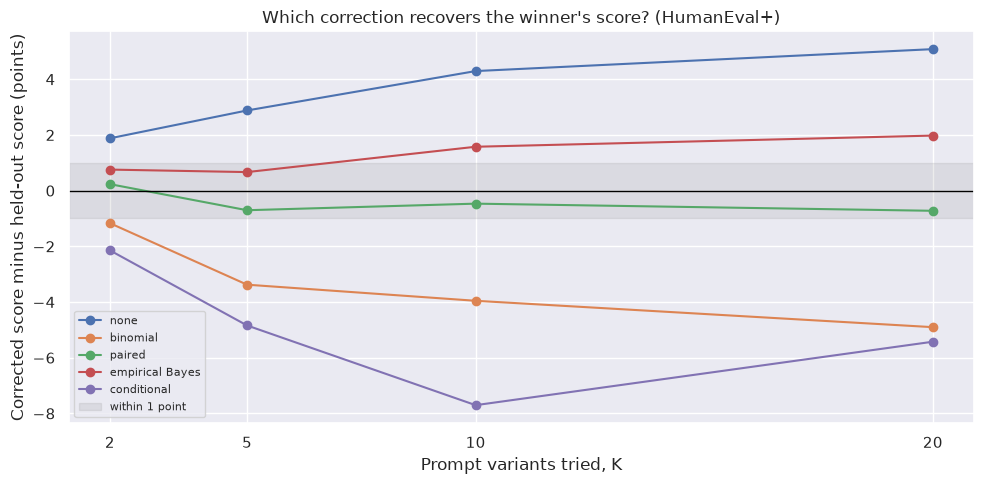

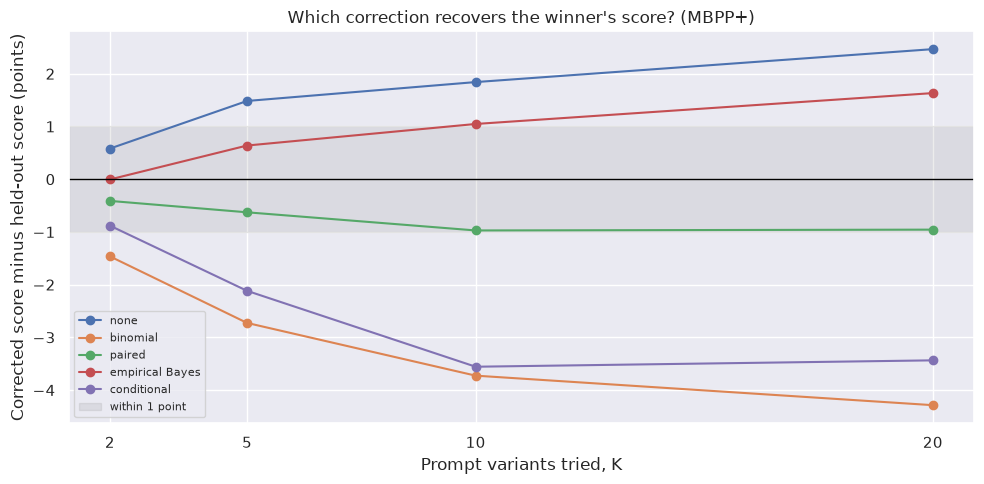

In [13]:
# Plot the mean error of each correction.
for benchmark in rutils.BENCHMARKS:
    rutils.plot_correction_errors(variants, benchmark, figsize=config["figsize"])

# Part 3: Which correction to recommend? (Study H)

## Cell 3.1: The rule fixed in `preregistration_3.md`

- Keep the corrections (paired, empirical Bayes, conditional) whose mean error
  is within 1 point of 0 in every setting of Studies F and G
- Recommend the one with the lowest RMSE averaged over the settings

In [14]:
# Gather the settings and apply the rule.
summaries = {}
for (group, k), row in runs_pooled.iterrows():
    summaries[f"runs {group} K={k}"] = pd.DataFrame(
        {
            "mean_error": [row[f"error_{c}"] for c in CORRECTIONS],
            "rmse": [row[f"rmse_{c}"] for c in CORRECTIONS],
        },
        index=CORRECTIONS,
    )
for (benchmark, k), row in variants.iterrows():
    summaries[f"variants {benchmark} K={k}"] = pd.DataFrame(
        {
            "mean_error": [row[f"error_{c}"] for c in CORRECTIONS],
            "rmse": [row[f"rmse_{c}"] for c in CORRECTIONS],
        },
        index=CORRECTIONS,
    )
rule_table, recommended = utils.choose_shrinkage_rule(summaries)
display(rule_table.round(3))
print(f"Recommended correction: {recommended}")

,max_abs_mean_error,mean_rmse,passes
paired,0.972,4.328,True
empirical_bayes,1.977,4.388,False
conditional,7.704,16.711,False


Recommended correction: paired


## Cell 3.2: Why the conditional estimate misses, and the hybrid fix (extra look)

- Not in `preregistration_3.md`: added after Study F showed the conditional
  estimate with a mean error of several points below 0
- The conditional estimate is right on the median, but when the winner only
  just won, it falls far below the score, at times below 0
- The hybrid estimate of the same paper also assumes that the winner's mean
  is within an interval that covers all the means at once with a 99.5%
  chance, so it stays within about 3 standard deviations of the score
- The draws and trials are those of Parts 1 and 2; the rule of Cell 3.1 is
  then applied again with the hybrid estimate as a fourth candidate

In [15]:
# Collect the errors of the conditional and hybrid estimates, in points.
frames = []
for (key, k), draws in runs_draws.items():
    frames.append(
        pd.DataFrame(
            {
                "setting": f"runs {key[0]} K={k}",
                "conditional": 100 * (draws["conditional"] - draws["truth"]),
                "hybrid": 100 * (draws["hybrid"] - draws["truth"]),
                "below_zero": draws["conditional"] < 0,
            }
        )
    )
for (benchmark, k), trials in variant_trials.items():
    truth = trials["evaluation_score"]
    frames.append(
        pd.DataFrame(
            {
                "setting": f"variants {benchmark} K={k}",
                "conditional": 100 * (trials["conditional"] - truth),
                "hybrid": 100 * (trials["hybrid"] - truth),
                "below_zero": trials["conditional"] < 0,
            }
        )
    )
errors = pd.concat(frames, ignore_index=True)
by_setting = errors.groupby("setting", sort=False)
tails = pd.DataFrame(
    {
        "conditional_median": by_setting["conditional"].median(),
        "conditional_5%": by_setting["conditional"].quantile(0.05),
        "conditional_below_0": 100 * by_setting["below_zero"].mean(),
        "hybrid_mean": by_setting["hybrid"].mean(),
        "hybrid_5%": by_setting["hybrid"].quantile(0.05),
        "hybrid_rmse": np.sqrt(
            by_setting["hybrid"].apply(lambda e: (e**2).mean())
        ),
    }
)
display(tails.round(2))

,conditional_median,conditional_5%,conditional_below_0,hybrid_mean,hybrid_5%,hybrid_rmse
setting,,,,,,
runs public K=2,0.39,-14.52,2.18,-0.57,-9.44,3.98
runs public K=5,0.71,-25.62,4.29,-0.65,-9.73,4.64
runs public K=10,1.06,-30.47,5.18,-0.64,-9.70,4.90
runs public K=20,1.45,-32.47,5.32,-0.33,-9.53,5.02
runs local K=2,0.87,-6.82,0.08,0.36,-6.47,3.68
runs local K=3,0.31,-14.57,0.63,-0.42,-8.16,3.39
variants humaneval K=2,0.45,-23.12,1.40,-0.11,-15.57,9.15
variants humaneval K=5,-0.71,-36.14,2.80,-1.47,-19.50,10.35
variants humaneval K=10,-0.88,-54.43,4.20,-1.46,-19.70,10.56


In [16]:
# Apply the rule of Cell 3.1 with the hybrid estimate as a candidate.
hybrid_summaries = {}
for setting, summary in summaries.items():
    # Every cell has the same number of draws, so pooling the draws gives the
    # mean errors of Cell 3.1.
    conditional = errors.loc[errors["setting"] == setting, "conditional"]
    hdbg.dassert_lt(
        abs(conditional.mean() - summary.loc["conditional", "mean_error"]),
        1e-9,
    )
    hybrid = errors.loc[errors["setting"] == setting, "hybrid"]
    hybrid_row = pd.DataFrame(
        {"mean_error": [hybrid.mean()], "rmse": [np.sqrt((hybrid**2).mean())]},
        index=["hybrid"],
    )
    hybrid_summaries[setting] = pd.concat([summary, hybrid_row])
hybrid_table, hybrid_recommended = utils.choose_shrinkage_rule(
    hybrid_summaries,
    candidates=("paired", "empirical_bayes", "conditional", "hybrid"),
)
display(hybrid_table.round(3))
print(
    f"Recommended with the hybrid estimate as a candidate: {hybrid_recommended}"
)

,max_abs_mean_error,mean_rmse,passes
paired,0.972,4.328,True
empirical_bayes,1.977,4.388,False
conditional,7.704,16.711,False
hybrid,1.474,6.486,False


Recommended with the hybrid estimate as a candidate: paired


# Part 4: The protocol on the SWE-bench Verified leaderboard

## Cell 4.1: The report of the top agents

- `report_agent_scores()` gives, for each agent, its score with a 95%
  interval, its rank interval, the paired test against the next agent
  (Holm-adjusted), and the tasks that would resolve that gap
- The leader is also reported with its score corrected for having been
  picked first among the 173 submissions, with the correction recommended
  in Cell 3.1 (the conditional estimate if none passed)
  - 2 agents tie for first with 396 of the 500 tasks; the one listed first
    gets the correction
- Cell 4.2 shows the leader under every correction, since the 173 agents
  are not equal variants, which some of the corrections assume

In [17]:
# Report the whole leaderboard and show the top 15.
outcomes, submissions, tasks = utils.load_swebench_dataset(
    config["swebench_dir"]
)
leader_correction = recommended or "conditional"
report = utils.report_agent_scores(
    outcomes, correction=leader_correction, seed=config["seed"]
)
# Show the scores in points.
shown = report.head(15).copy()
points = ["score", "ci_low", "ci_high", "gap_next", "corrected"]
shown[points] = 100 * shown[points]
display(shown.round(2))
leader = report.index[0]
print(
    f"Leader: {100 * report.loc[leader, 'score']:.1f}%, corrected for being "
    f"picked first: {100 * report.loc[leader, 'corrected']:.1f}%"
)

,score,rank_low,rank_high,p_first,ci_low,ci_high,gap_next,p_next_holm,tasks_to_resolve,corrected
submission,,,,,,,,,,
20251205_sonar-foundation-agent_claude-opus-4-5,79.2,1.00,6.00,0.32,75.60,82.6,0.0,1.0,inf,75.15
20251215_livesweagent_claude-opus-4-5,79.2,1.00,6.00,0.34,75.60,82.6,0.4,1.0,64875.16,NaN
20250928_trae_doubao_seed_code,78.8,1.00,8.50,0.29,75.20,82.2,1.2,1.0,7419.82,NaN
20251127_openhands_claude-opus-4-5,77.6,2.00,14.00,0.01,73.80,81.2,0.2,1.0,200539.66,NaN
20251120_livesweagent_gemini-3-pro-preview,77.4,2.00,14.50,0.02,73.80,81.0,0.6,1.0,25770.58,NaN
20250804_epam-ai-run-claude-4-sonnet,76.8,2.00,17.50,0.01,73.19,80.4,0.0,1.0,inf,NaN
20250902_atlassian-rovo-dev,76.8,2.50,16.50,0.00,73.00,80.4,0.0,1.0,inf,NaN
20260217_mini-v2.0.0_claude-4-5-opus-high,76.8,3.00,18.51,0.00,72.80,80.4,0.4,1.0,62909.01,NaN
20250819_ACoder,76.4,3.00,20.00,0.00,72.60,80.0,0.6,1.0,27518.27,NaN


Leader: 79.2%, corrected for being picked first: 75.1%


## Cell 4.2: The leader under every correction (extra look)

- Not in `preregistration_3.md`
- The binomial and paired rules assume that all the agents are equal, which
  the 173 submissions are not, so they correct too much here; empirical Bayes
  shrinks toward the mean of all the agents; the conditional estimate only
  looks at the agents that could have beaten the leader
  - A check from Milestone 3: in `skill_vs_luck.example.ipynb` (Cell 6.2),
    the leader of one half of the tasks scores 2.0 points less on the other
    half, with 250 tasks per half; with all 500 tasks the noise is smaller,
    so the leader's real inflation is likely 2 points or less
- The hybrid estimate of Cell 3.2 is also shown

In [18]:
# Correct the leader's score with each correction.
ordered = outcomes.loc[report.index].to_numpy(dtype=float)
leader_estimates = utils.correct_winner_score(ordered, 0, seed=config["seed"])
display((100 * pd.Series(leader_estimates)).round(2).to_frame("leader_score"))

,leader_score
none,79.20
binomial,74.30
paired,75.15
empirical_bayes,79.04
conditional,72.67
hybrid,73.09


# Part 5: Which predictions held?

## Cell 5.1: Predictions F1 to F3 and G0 to G5 against the results

In [19]:
# Check the predictions of Studies F and G.
predictions = rutils.check_selection_predictions(
    runs_pooled=runs_pooled,
    runs_cells=runs_cells,
    variants=variants,
    agreement=agreement,
    cochran=cochran,
)
display(predictions)

,prediction,observed,holds
F1,"Inflation within 20% of the prediction, every K","5 of 6 settings, ratios 1.00 to 1.41",False
F2,"Best of 5 runs at 0.8 is 1.5 points above, eac...","9 of 9 cells, smallest 2.26 points",True
F3,The binomial correction over-corrects the best...,mean error -1.68 points,True
G0,The baseline variant repeats phase 1 on 95% of...,"HumanEval+ 100.0%, MBPP+ 99.7%",True
G1,Cochran's Q rejects equal pass rates on 1 benc...,"HumanEval+ p 0.00202, MBPP+ p 1e-33",True
G2,At K = 20 the mean drop is at least 1 point,"HumanEval+ 5.08, MBPP+ 2.47",True
G3,At K = 20 the binomial correction over-corrects,"HumanEval+ -4.90, MBPP+ -4.29",True
G4,"The conditional mean error is within 1 point, ...",-7.70 to -0.88 points,False
G5,"At K = 20, empirical Bayes or conditional has ...","HumanEval+ paired, MBPP+ paired",False


# Part 6: Takeaways

- On the public samples, the best of K runs is above the runs left out by
  just what `sigma_run x E[max of K]` predicts: 1.2 points for K = 2 up to
  4.0 for K = 20, with ratios of 1.00 to 1.04
  - On our runs, with only 3 or 5 runs per cell, the inflation is 1.41 times
    the prediction at K = 2 (F1 did not hold), since `p_t (1 - p_t)` from few
    runs is too low; correcting for that brings the ratios to 1.20 and 1.06
    (Cell 1.4, an extra look)
  - The best of 5 runs at temperature 0.8 is 2.3 to 3.2 points above the runs
    left out, for each of the 9 public cells (F2 held)
- The 20 prompt variants differ for real: 50.0% to 60.4% on HumanEval+ and
  41.8% to 54.0% on MBPP+, with Cochran's Q p of 0.002 and about 1e-33 (G1
  held)
  - The line asking to handle edge cases costs 7 to 9 points on HumanEval+
    and 10 to 12 on MBPP+, and more of its answers hit the token limit
  - The baseline variant repeats the outcome of phase 1 on every HumanEval+
    task and on 377 of the 378 MBPP+ tasks (G0 held)
- Picked on half of the tasks, the best of K variants scores less on the
  other half: 1.9 points for K = 2 up to 5.1 for K = 20 on HumanEval+, and
  0.6 up to 2.5 on MBPP+ (G2 held)
- How the corrections did:
  - Binomial: corrects too much, more as K grows: -4.9 and -4.3 points at
    K = 20 (G3 held), and -1.7 for the best of 5 runs (F3 held)
  - Empirical Bayes: corrects too little as K grows, +2.0 on HumanEval+ and
    +1.6 on MBPP+ at K = 20, since the spread of the K scores also holds the
    real gaps between the variants
  - Conditional: right on the median, but its mean error is -0.9 to -7.7
    points (G4 did not hold) and its root mean squared error up to 31
    points: when the winner only just won, the estimate falls far below the
    score, under 0 in up to 5.3% of the draws
  - Paired: within 1 point in every setting of Studies F and G (worst
    -0.97), and the lowest root mean squared error at K = 20 on both
    benchmarks (G5 did not hold, since it named empirical Bayes or
    conditional)
- Rule H recommends the paired correction: it is the only candidate within
  1 point everywhere, with a mean root mean squared error of 4.3 points
  - The hybrid estimate cuts the root mean squared error of the conditional
    one by 1.5 to 3.8 times, but it still misses by up to 1.5 points, with a
    mean root mean squared error of 6.5, so the paired correction stays the
    recommendation (Cell 3.2, an extra look)
- On SWE-bench Verified, the paired correction takes the leader from 79.2%
  to 75.1%, and the 5 corrections range from 72.7% (conditional) to 79.0%
  (empirical Bayes)
  - The 173 agents are far from equal, so the paired rule likely corrects too
    much here: the leader of one half of the tasks loses only 2.0 points on
    the other half (Cell 4.2)
- 6 of the 9 predictions held (F2, F3, and G0 to G3), and F1, G4, and G5 did
  not; with Study E, 10 of the 15 predictions of `preregistration_3.md` held